# EN4554 Assignment 2: Convolutional Neural Networks

**Name:** _Add student name_  
**Index number:** _Add index number_  
**GitHub:** [CNN-with-CIFAR10](https://github.com/LahiruMJ11/CNN-with-CIFAR10)

This notebook contains the theory, implementations, experiments, results, and discussion for the assignment. It is designed to run on Google Colab with a T4 GPU and on a laptop with Apple MPS or CPU.

## Setup: Reproducible CIFAR-10 data pipeline

CIFAR-10 contains 60,000 RGB images of size $32\times32$ in 10 classes: 50,000 standard training images and 10,000 standard test images. Following the assignment, the standard training portion is divided into 45,000 training images and 5,000 validation images. The validation partition is used for model and hyperparameter decisions, while the standard test partition is reserved for the single final evaluation in Task 4.

To prevent data leakage, the per-channel mean and population standard deviation are calculated from only the 45,000-image training partition. If $x_{nchw}$ is a pixel scaled to $[0,1]$, the channel statistics are

$$\mu_c=\frac{1}{NHW}\sum_{n,h,w}x_{nchw},\qquad \sigma_c=\sqrt{\frac{1}{NHW}\sum_{n,h,w}x_{nchw}^2-\mu_c^2}.$$

Every training and validation image is then normalized using $\hat{x}_c=(x_c-\mu_c)/\sigma_c$. Fixed seeds make the split and data-loading order repeatable. Exact numerical results can still vary slightly across PyTorch versions and hardware backends.

In [2]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import CIFAR10

SEED = 42
DATA_ROOT = Path("./data")
TRAIN_SIZE = 45_000
VAL_SIZE = 5_000
BATCH_SIZE = 128

def seed_everything(seed: int = SEED) -> None:
    """Seed Python, NumPy, and PyTorch and request deterministic behavior."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

def select_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

seed_everything()
device = select_device()
print(f"PyTorch version: {torch.__version__}")
print(f"Selected device: {device}")

PyTorch version: 2.14.1
Selected device: mps


The device-selection order is CUDA (including a Colab T4), Apple MPS, and finally CPU. The data split is independent of the selected device because it uses a dedicated CPU generator.

In [3]:
# download=True downloads on a fresh Colab runtime and reuses the verified local archive here.
raw_dataset = CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

assert len(raw_dataset) == TRAIN_SIZE + VAL_SIZE
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_dataset), generator=split_generator).tolist()
train_indices = permutation[:TRAIN_SIZE]
val_indices = permutation[TRAIN_SIZE:]

assert len(train_indices) == TRAIN_SIZE
assert len(val_indices) == VAL_SIZE
assert set(train_indices).isdisjoint(val_indices)

raw_train_subset = Subset(raw_dataset, train_indices)
print(f"Original training portion: {len(raw_dataset):,}")
print(f"Training partition: {len(train_indices):,}")
print(f"Validation partition: {len(val_indices):,}")

Original training portion: 50,000
Training partition: 45,000
Validation partition: 5,000


The printed sizes and disjointness assertion confirm the required 45,000/5,000 partition. A dedicated generator with seed 42 ensures that every experiment can reuse exactly the same indices.

In [4]:
def compute_channel_statistics(dataset, batch_size: int = 512):
    """Return per-channel population mean and standard deviation."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0

    for images, _ in loader:
        images = images.to(torch.float64)
        channel_sum += images.sum(dim=(0, 2, 3))
        channel_squared_sum += images.square().sum(dim=(0, 2, 3))
        pixel_count += images.shape[0] * images.shape[2] * images.shape[3]

    mean = channel_sum / pixel_count
    variance = channel_squared_sum / pixel_count - mean.square()
    std = variance.clamp_min(0).sqrt()
    return mean.to(torch.float32), std.to(torch.float32)

channel_mean, channel_std = compute_channel_statistics(raw_train_subset)
assert torch.all(channel_std > 0)

statistics_table = pd.DataFrame(
    {"mean": channel_mean.numpy(), "population std": channel_std.numpy()},
    index=["red", "green", "blue"],
)
statistics_table

,mean,population std
red,0.491656,0.247081
green,0.482334,0.243509
blue,0.446679,0.261581


The channel values differ, so a single global normalization would not centre and scale each colour channel correctly. These values were measured after the seeded split using only training pixels; validation pixels and the standard test set made no contribution.

In [5]:
normalization = transforms.Normalize(
    mean=channel_mean.tolist(),
    std=channel_std.tolist(),
)
normalized_transform = transforms.Compose([transforms.ToTensor(), normalization])

# Both subsets refer to the standard training portion; the test portion is not loaded.
normalized_dataset = CIFAR10(
    root=DATA_ROOT, train=True, download=False, transform=normalized_transform
)
train_dataset = Subset(normalized_dataset, train_indices)
val_dataset = Subset(normalized_dataset, val_indices)

num_workers = 2 if device.type == "cuda" else 0
pin_memory = device.type == "cuda"
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    generator=loader_generator,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
)

images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 32, 32)
assert labels.min() >= 0 and labels.max() < 10
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Example batch: images {tuple(images.shape)}, labels {tuple(labels.shape)}")

Training batches: 352
Validation batches: 40
Example batch: images (128, 3, 32, 32), labels (128,)


The loaders provide channel-first $3\times32\times32$ tensors and integer targets from 0 to 9. Training batches are shuffled reproducibly, whereas validation order remains fixed for consistent evaluation.

In [6]:
targets = np.asarray(raw_dataset.targets)
train_counts = np.bincount(targets[train_indices], minlength=10)
val_counts = np.bincount(targets[val_indices], minlength=10)
class_distribution = pd.DataFrame(
    {"training": train_counts, "validation": val_counts},
    index=raw_dataset.classes,
)
class_distribution.loc["Total"] = class_distribution.sum(axis=0)
class_distribution

,training,validation
airplane,4512,488
automobile,4488,512
bird,4468,532
cat,4529,471
deer,4529,471
dog,4486,514
frog,4493,507
horse,4500,500
ship,4496,504
truck,4499,501


The seeded random split keeps every class well represented in both partitions, with counts close to the expected 90%/10% division. The totals also independently confirm the required partition sizes.

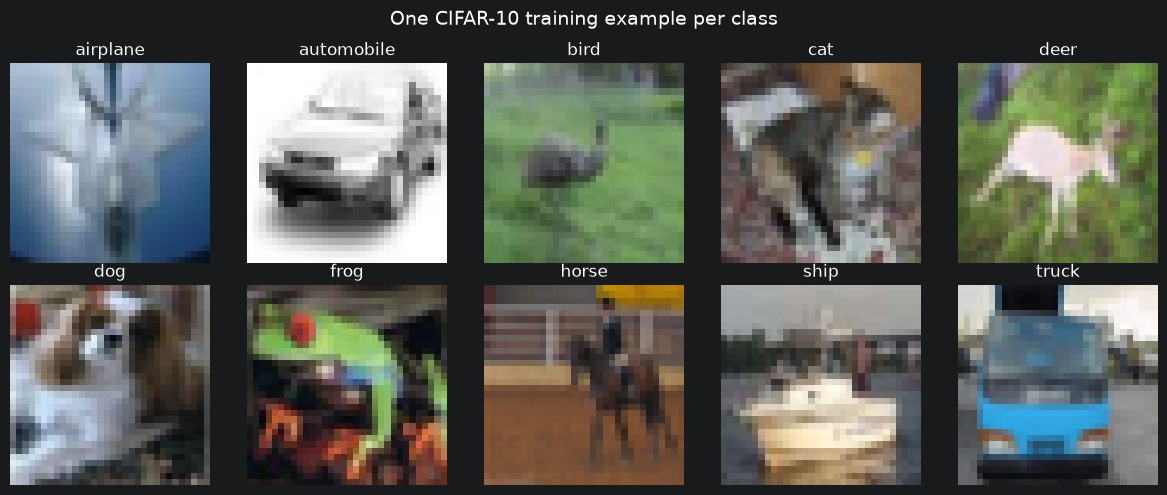

In [7]:
# Select one training example from each class without accessing test data.
example_indices = []
for class_id in range(10):
    example_indices.append(next(i for i in train_indices if targets[i] == class_id))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, (axis, dataset_index) in enumerate(zip(axes.flat, example_indices)):
    image, label = raw_dataset[dataset_index]
    axis.imshow(image.permute(1, 2, 0))
    axis.set_title(raw_dataset.classes[label])
    axis.axis("off")
fig.suptitle("One CIFAR-10 training example per class", fontsize=14)
fig.tight_layout()
plt.show()

The examples confirm that the labels and image layout were loaded correctly. CIFAR-10 images are small and visually varied, which makes classification non-trivial and motivates learning features rather than relying on individual pixels.

### Test-set policy

No `train=False` CIFAR-10 dataset or test loader is created in this setup. The final model will be selected using validation data, and the standard test set will be instantiated and evaluated exactly once in Task 4, as required by the assignment.

## Task 1(a): Manual backpropagation and MLP

Backpropagation applies the chain rule from the scalar loss towards earlier operations. Each component caches the information required during its forward pass, then its `backward` method receives the gradient with respect to its output and returns the gradient with respect to its input. Parameter gradients are stored separately for later optimization.

The manual path below uses PyTorch tensors only as arrays for numerical operations. Its parameters have `requires_grad=False`, and it does not use `torch.nn` layers, `loss.backward()`, or `torch.autograd` to calculate gradients. Formal comparison with an isolated autograd reference belongs to Task 1(b).

### Manual Linear layer

For a row-wise minibatch, a Linear layer computes

$$Y=XW+b,$$

where $X\in\mathbb{R}^{N\times D}$, $W\in\mathbb{R}^{D\times M}$, $b\in\mathbb{R}^{M}$, and $Y\in\mathbb{R}^{N\times M}$. Given upstream gradient $G=\partial L/\partial Y$, the explicit backward equations are

$$\frac{\partial L}{\partial X}=GW^T,\qquad \frac{\partial L}{\partial W}=X^TG,\qquad \frac{\partial L}{\partial b}=\sum_{n=1}^{N}G_{n,:}.$$

The loss will already supply the factor $1/N$ for mean reduction, so the Linear layer must not divide its gradients by the batch size again.

In [8]:
class ManualLinear:
    """A fully connected layer with an explicit analytical backward pass."""

    def __init__(self, in_features, out_features, *, device=None, dtype=torch.float32):
        if in_features <= 0 or out_features <= 0:
            raise ValueError("in_features and out_features must be positive")
        self.in_features = in_features
        self.out_features = out_features
        # Kaiming-style scaling is an implementation choice for the ReLU MLP.
        scale = (2.0 / in_features) ** 0.5
        self.weight = torch.randn(
            in_features, out_features, device=device, dtype=dtype
        ) * scale
        self.bias = torch.zeros(out_features, device=device, dtype=dtype)
        self.grad_weight = torch.zeros_like(self.weight)
        self.grad_bias = torch.zeros_like(self.bias)
        self._input = None

    def forward(self, inputs):
        if inputs.ndim != 2 or inputs.shape[1] != self.in_features:
            raise ValueError(
                f"Expected inputs with shape (N, {self.in_features}), "
                f"received {tuple(inputs.shape)}"
            )
        self._input = inputs
        return inputs @ self.weight + self.bias

    def backward(self, grad_output):
        if self._input is None:
            raise RuntimeError("forward must be called before backward")
        expected_shape = (self._input.shape[0], self.out_features)
        if tuple(grad_output.shape) != expected_shape:
            raise ValueError(
                f"Expected grad_output with shape {expected_shape}, "
                f"received {tuple(grad_output.shape)}"
            )
        self.grad_weight = self._input.T @ grad_output
        self.grad_bias = grad_output.sum(dim=0)
        return grad_output @ self.weight.T

### Manual ReLU

ReLU applies $A=\max(0,Z)$ elementwise. Using zero as the subgradient at $Z=0$, its backward operation is

$$G_Z=G_A\odot\mathbf{1}_{Z>0}.$$

The Boolean activation mask implements the required Jacobian-vector product directly; constructing the full diagonal Jacobian would waste memory.

In [9]:
class ManualReLU:
    """Elementwise ReLU with zero subgradient at the origin."""

    def __init__(self):
        self._positive_mask = None

    def forward(self, inputs):
        self._positive_mask = inputs > 0
        return torch.where(self._positive_mask, inputs, torch.zeros_like(inputs))

    def backward(self, grad_output):
        if self._positive_mask is None:
            raise RuntimeError("forward must be called before backward")
        if grad_output.shape != self._positive_mask.shape:
            raise ValueError("grad_output must have the same shape as the ReLU input")
        return grad_output * self._positive_mask

### Manual softmax cross-entropy

For logits $S\in\mathbb{R}^{N\times K}$, softmax assigns probability $p_{ij}=e^{S_{ij}}/\sum_k e^{S_{ik}}$. The mean cross-entropy for integer labels $y_i$ is

$$L=-\frac{1}{N}\sum_i\log p_{i,y_i}.$$

Subtracting each row's maximum logit before exponentiation leaves its probabilities unchanged and prevents overflow. Differentiating the combined loss gives

$$\frac{\partial L}{\partial S}=\frac{P-Y_{\mathrm{onehot}}}{N}.$$

The implementation uses integer indexing, so it does not need to materialize the one-hot target matrix.

In [10]:
class ManualSoftmaxCrossEntropy:
    """Numerically stable mean softmax cross-entropy with manual gradient."""

    def __init__(self):
        self._probabilities = None
        self._targets = None

    def forward(self, logits, targets):
        if logits.ndim != 2:
            raise ValueError("logits must have shape (N, K)")
        if targets.ndim != 1 or targets.shape[0] != logits.shape[0]:
            raise ValueError("targets must have shape (N,)")
        if targets.dtype != torch.long:
            raise TypeError("targets must contain torch.long class indices")
        if bool(((targets < 0) | (targets >= logits.shape[1])).any().item()):
            raise ValueError("target index is outside the class range")

        shifted_logits = logits - logits.max(dim=1, keepdim=True).values
        exp_logits = shifted_logits.exp()
        normalizers = exp_logits.sum(dim=1, keepdim=True)
        self._probabilities = exp_logits / normalizers
        self._targets = targets

        row_indices = torch.arange(logits.shape[0], device=logits.device)
        log_probabilities = shifted_logits - normalizers.log()
        return -log_probabilities[row_indices, targets].mean()

    def backward(self):
        if self._probabilities is None or self._targets is None:
            raise RuntimeError("forward must be called before backward")
        batch_size = self._targets.shape[0]
        row_indices = torch.arange(batch_size, device=self._targets.device)
        grad_logits = self._probabilities.clone()
        grad_logits[row_indices, self._targets] -= 1.0
        return grad_logits / batch_size

### Assemble the manual MLP

Each normalized CIFAR-10 image is flattened from $(3,32,32)$ to 3,072 features. The model uses one 256-unit hidden layer, chosen as a modest laptop-friendly width rather than an assignment-mandated value:

```text
(N, 3072) -> Linear(3072, 256) -> ReLU -> Linear(256, 10) -> logits
```

The backward pass traverses those components in the exact reverse order. Softmax cross-entropy remains a separate component because it converts the final logits and labels into the initial gradient for the model.

In [11]:
class ManualMLP:
    """One-hidden-layer CIFAR-10 MLP assembled from manual components."""

    def __init__(
        self, input_dim=3 * 32 * 32, hidden_dim=256, num_classes=10,
        *, device=None, dtype=torch.float32
    ):
        self.linear1 = ManualLinear(
            input_dim, hidden_dim, device=device, dtype=dtype
        )
        self.relu = ManualReLU()
        self.linear2 = ManualLinear(
            hidden_dim, num_classes, device=device, dtype=dtype
        )

    def forward(self, inputs):
        hidden_pre_activation = self.linear1.forward(inputs)
        hidden_activation = self.relu.forward(hidden_pre_activation)
        return self.linear2.forward(hidden_activation)

    def backward(self, grad_logits):
        grad_hidden = self.linear2.backward(grad_logits)
        grad_hidden_pre_activation = self.relu.backward(grad_hidden)
        return self.linear1.backward(grad_hidden_pre_activation)

    def named_parameters_and_gradients(self):
        return [
            ("linear1.weight", self.linear1.weight, self.linear1.grad_weight),
            ("linear1.bias", self.linear1.bias, self.linear1.grad_bias),
            ("linear2.weight", self.linear2.weight, self.linear2.grad_weight),
            ("linear2.bias", self.linear2.bias, self.linear2.grad_bias),
        ]

In [12]:
# A small real training minibatch checks the complete manual forward/backward path.
demo_images, demo_targets = next(iter(train_loader))
demo_inputs = demo_images[:8].reshape(8, -1).to(device)
demo_targets = demo_targets[:8].to(device)

manual_mlp = ManualMLP(hidden_dim=256, device=device)
manual_loss = ManualSoftmaxCrossEntropy()
demo_logits = manual_mlp.forward(demo_inputs)
demo_loss = manual_loss.forward(demo_logits, demo_targets)
demo_grad_logits = manual_loss.backward()
demo_grad_inputs = manual_mlp.backward(demo_grad_logits)

assert demo_logits.shape == (8, 10)
assert demo_loss.ndim == 0 and bool(torch.isfinite(demo_loss).item())
assert demo_grad_logits.shape == demo_logits.shape
assert demo_grad_inputs.shape == demo_inputs.shape
assert bool(torch.isfinite(demo_grad_inputs).all().item())
assert torch.allclose(
    manual_loss._probabilities.sum(dim=1),
    torch.ones(8, device=device),
    atol=1e-6,
)
assert torch.allclose(
    demo_grad_logits.sum(dim=1),
    torch.zeros(8, device=device),
    atol=1e-6,
)
assert demo_logits.grad_fn is None and not demo_logits.requires_grad

gradient_rows = []
for name, parameter, gradient in manual_mlp.named_parameters_and_gradients():
    assert parameter.shape == gradient.shape
    assert not parameter.requires_grad
    assert bool(torch.isfinite(gradient).all().item())
    gradient_rows.append(
        {
            "parameter": name,
            "parameter shape": str(tuple(parameter.shape)),
            "gradient shape": str(tuple(gradient.shape)),
            "gradient L2 norm": gradient.norm().item(),
        }
    )

parameter_count = sum(
    parameter.numel()
    for _, parameter, _ in manual_mlp.named_parameters_and_gradients()
)
print(f"Demo input shape: {tuple(demo_inputs.shape)}")
print(f"Logit shape: {tuple(demo_logits.shape)}")
print(f"Mean cross-entropy loss: {demo_loss.item():.6f}")
print(f"Input-gradient shape: {tuple(demo_grad_inputs.shape)}")
print(f"Trainable parameter count: {parameter_count:,}")
pd.DataFrame(gradient_rows)

Demo input shape: (8, 3072)
Logit shape: (8, 10)
Mean cross-entropy loss: 2.731329
Input-gradient shape: (8, 3072)
Trainable parameter count: 789,258


,parameter,parameter shape,gradient shape,gradient L2 norm
0,linear1.weight,"(3072, 256)","(3072, 256)",16.202597
1,linear1.bias,"(256,)","(256,)",0.389378
2,linear2.weight,"(256, 10)","(256, 10)",4.882580
3,linear2.bias,"(10,)","(10,)",0.393426


The smoke test sends eight normalized, flattened training images through the complete manual path. At random initialization it produced a finite mean loss of 2.731329; this is an implementation check rather than a classification-performance result. The $(8,10)$ logits, $(8,3072)$ input gradient, and matching parameter/gradient shapes show that the components connect correctly. Softmax probabilities sum to one, each row of its logit gradient sums to zero, and the table shows nonzero finite gradient norms for both Linear layers. These structural checks do not establish numerical gradient correctness; Task 1(b) will test the same formulas independently using autograd and centred finite differences.

## Task 1(b): Gradient verification

A forward pass can produce plausible values even when a transpose, sign, batch average, or activation mask is wrong. The analytical gradients are therefore checked against two independent references: PyTorch autograd and centred finite differences. The checks use a tiny deterministic MLP on CPU in `float64`; perturbing every coordinate of the full CIFAR-10 model would be unnecessarily expensive.

For scalar loss $f$ and coordinate $\theta_i$, the centred finite-difference estimate is

$$g_i^{\mathrm{FD}}\approx\frac{f(\theta_i+h)-f(\theta_i-h)}{2h}.$$

The experiment uses $h=10^{-5}$. This is small enough for the $O(h^2)$ truncation error to be useful in double precision without making subtraction rounding error dominant. All MLP ReLU preactivations are checked to remain away from zero, where ReLU is not differentiable.

### Error metrics and tolerances

For each coordinate, the reported symmetric relative error is

$$r_i=\frac{|g_i^{\mathrm{manual}}-g_i^{\mathrm{reference}}|}{\max(10^{-12},|g_i^{\mathrm{manual}}|+|g_i^{\mathrm{reference}}|)}.$$

Each table entry reports $\max_i r_i$ together with the maximum absolute error. Absolute error is included because a relative error can look large when both gradients are nearly zero. `torch.allclose` checks every coordinate using $|a_i-b_i|\leq\mathrm{atol}+\mathrm{rtol}|b_i|$. The chosen tolerances are `rtol=1e-9, atol=1e-11` for analytical versus autograd gradients and `rtol=1e-5, atol=1e-7` for finite differences, whose approximation and rounding errors are larger. These are documented experimental choices, not lecturer-prescribed values.

In [13]:
# Build a small, smooth test case for the manual end-to-end path.
CHECK_BATCH_SIZE = 4
CHECK_INPUT_DIM = 5
CHECK_HIDDEN_DIM = 4
CHECK_NUM_CLASSES = 3
FD_STEP = 1e-5
RELATIVE_EPSILON = 1e-12
AUTOGRAD_RTOL, AUTOGRAD_ATOL = 1e-9, 1e-11
FD_RTOL, FD_ATOL = 1e-5, 1e-7
check_device = torch.device("cpu")
check_dtype = torch.float64
check_targets = torch.tensor([0, 1, 2, 1], dtype=torch.long)

# Select a deterministic point with positive and negative ReLU inputs,
# all separated from the non-differentiable value zero.
for check_seed in range(12_345, 12_445):
    torch.manual_seed(check_seed)
    check_inputs = torch.randn(
        CHECK_BATCH_SIZE, CHECK_INPUT_DIM, dtype=check_dtype
    )
    check_model = ManualMLP(
        input_dim=CHECK_INPUT_DIM,
        hidden_dim=CHECK_HIDDEN_DIM,
        num_classes=CHECK_NUM_CLASSES,
        device=check_device,
        dtype=check_dtype,
    )
    check_preactivations = (
        check_inputs @ check_model.linear1.weight + check_model.linear1.bias
    )
    minimum_relu_margin = check_preactivations.abs().min().item()
    has_both_relu_regions = bool(
        (check_preactivations > 0).any().item()
        and (check_preactivations < 0).any().item()
    )
    if minimum_relu_margin > 0.1 and has_both_relu_regions:
        break
else:
    raise RuntimeError("Could not construct a smooth deterministic ReLU test point")

check_loss_function = ManualSoftmaxCrossEntropy()
manual_check_logits = check_model.forward(check_inputs)
manual_check_loss = check_loss_function.forward(
    manual_check_logits, check_targets
)
manual_grad_logits = check_loss_function.backward().clone()
manual_grad_hidden = check_model.linear2.backward(manual_grad_logits)
manual_grad_preactivations = check_model.relu.backward(manual_grad_hidden)
manual_grad_inputs = check_model.linear1.backward(
    manual_grad_preactivations
).clone()

manual_gradients = {
    "loss logits": manual_grad_logits.clone(),
    "MLP input": manual_grad_inputs,
    "linear1.weight": check_model.linear1.grad_weight.clone(),
    "linear1.bias": check_model.linear1.grad_bias.clone(),
    "linear2.weight": check_model.linear2.grad_weight.clone(),
    "linear2.bias": check_model.linear2.grad_bias.clone(),
}

# A separate ReLU component check uses values safely away from zero.
relu_check_inputs = torch.tensor(
    [[-2.0, -0.5, 0.25, 1.5]], dtype=check_dtype
)
relu_upstream = torch.tensor(
    [[0.4, -1.2, 2.0, -0.7]], dtype=check_dtype
)
relu_check = ManualReLU()
relu_check.forward(relu_check_inputs)
manual_gradients["ReLU input"] = relu_check.backward(relu_upstream).clone()

print(f"Gradient-check seed: {check_seed}")
print(f"Minimum absolute MLP ReLU preactivation: {minimum_relu_margin:.6f}")
print(f"Manual tiny-MLP loss: {manual_check_loss.item():.12f}")

Gradient-check seed: 12345
Minimum absolute MLP ReLU preactivation: 0.124134
Manual tiny-MLP loss: 1.414826545279


### Isolated autograd reference

The following cell is intentionally separate from the manual implementation. It copies the same values into leaf tensors with `requires_grad=True`, reconstructs the MLP using standard tensor operations, and calls PyTorch's `backward()` only to obtain independent reference gradients.

In [14]:
import torch.nn.functional as F

reference_inputs = check_inputs.detach().clone().requires_grad_(True)
reference_w1 = check_model.linear1.weight.detach().clone().requires_grad_(True)
reference_b1 = check_model.linear1.bias.detach().clone().requires_grad_(True)
reference_w2 = check_model.linear2.weight.detach().clone().requires_grad_(True)
reference_b2 = check_model.linear2.bias.detach().clone().requires_grad_(True)

reference_preactivations = reference_inputs @ reference_w1 + reference_b1
reference_hidden = F.relu(reference_preactivations)
reference_logits = reference_hidden @ reference_w2 + reference_b2
reference_logits.retain_grad()
reference_loss = F.cross_entropy(reference_logits, check_targets, reduction="mean")
reference_loss.backward()

autograd_gradients = {
    "loss logits": reference_logits.grad.detach().clone(),
    "MLP input": reference_inputs.grad.detach().clone(),
    "linear1.weight": reference_w1.grad.detach().clone(),
    "linear1.bias": reference_b1.grad.detach().clone(),
    "linear2.weight": reference_w2.grad.detach().clone(),
    "linear2.bias": reference_b2.grad.detach().clone(),
}

reference_relu_inputs = relu_check_inputs.detach().clone().requires_grad_(True)
reference_relu_scalar = (F.relu(reference_relu_inputs) * relu_upstream).sum()
reference_relu_scalar.backward()
autograd_gradients["ReLU input"] = reference_relu_inputs.grad.detach().clone()

assert torch.allclose(
    manual_check_loss, reference_loss.detach(), rtol=1e-12, atol=1e-12
)
print(f"Autograd tiny-MLP loss: {reference_loss.item():.12f}")

Autograd tiny-MLP loss: 1.414826545279


In [15]:
def centered_finite_difference(tensor, scalar_function, step=FD_STEP):
    """Estimate every coordinate gradient while restoring each value."""
    gradient = torch.zeros_like(tensor)
    flat_tensor = tensor.view(-1)
    flat_gradient = gradient.view(-1)

    for index in range(flat_tensor.numel()):
        original_value = flat_tensor[index].item()
        flat_tensor[index] = original_value + step
        loss_plus = scalar_function().item()
        flat_tensor[index] = original_value - step
        loss_minus = scalar_function().item()
        flat_tensor[index] = original_value
        flat_gradient[index] = (loss_plus - loss_minus) / (2.0 * step)

    return gradient

def current_manual_mlp_loss():
    logits = check_model.forward(check_inputs)
    loss_function = ManualSoftmaxCrossEntropy()
    return loss_function.forward(logits, check_targets)

finite_difference_gradients = {}
mlp_tensors_to_check = {
    "MLP input": check_inputs,
    "linear1.weight": check_model.linear1.weight,
    "linear1.bias": check_model.linear1.bias,
    "linear2.weight": check_model.linear2.weight,
    "linear2.bias": check_model.linear2.bias,
}
for name, tensor in mlp_tensors_to_check.items():
    finite_difference_gradients[name] = centered_finite_difference(
        tensor, current_manual_mlp_loss
    )

fd_logits = manual_check_logits.detach().clone()
finite_difference_gradients["loss logits"] = centered_finite_difference(
    fd_logits,
    lambda: ManualSoftmaxCrossEntropy().forward(fd_logits, check_targets),
)

fd_relu_inputs = relu_check_inputs.clone()
finite_difference_gradients["ReLU input"] = centered_finite_difference(
    fd_relu_inputs,
    lambda: (
        torch.where(fd_relu_inputs > 0, fd_relu_inputs, torch.zeros_like(fd_relu_inputs))
        * relu_upstream
    ).sum(),
)

print(f"Centred finite differences completed with h={FD_STEP:g}.")

Centred finite differences completed with h=1e-05.


In [16]:
def gradient_errors(manual, reference, epsilon=RELATIVE_EPSILON):
    absolute_error = (manual - reference).abs()
    denominator = torch.maximum(
        manual.abs() + reference.abs(),
        torch.full_like(manual, epsilon),
    )
    relative_error = absolute_error / denominator
    return absolute_error.max().item(), relative_error.max().item()

comparison_rows = []
comparison_order = [
    "ReLU input",
    "loss logits",
    "MLP input",
    "linear1.weight",
    "linear1.bias",
    "linear2.weight",
    "linear2.bias",
]
for name in comparison_order:
    manual_gradient = manual_gradients[name]
    autograd_gradient = autograd_gradients[name]
    fd_gradient = finite_difference_gradients[name]
    auto_abs, auto_rel = gradient_errors(manual_gradient, autograd_gradient)
    fd_abs, fd_rel = gradient_errors(manual_gradient, fd_gradient)
    comparison_rows.append(
        {
            "component / tensor": name,
            "autograd max abs": auto_abs,
            "autograd max relative": auto_rel,
            "autograd allclose": torch.allclose(
                manual_gradient, autograd_gradient,
                rtol=AUTOGRAD_RTOL, atol=AUTOGRAD_ATOL,
            ),
            "finite diff max abs": fd_abs,
            "finite diff max relative": fd_rel,
            "finite diff allclose": torch.allclose(
                manual_gradient, fd_gradient, rtol=FD_RTOL, atol=FD_ATOL
            ),
        }
    )

gradient_comparison = pd.DataFrame(comparison_rows).set_index(
    "component / tensor"
)
assert gradient_comparison["autograd allclose"].all()
assert gradient_comparison["finite diff allclose"].all()
gradient_comparison

,autograd max abs,autograd max relative,autograd allclose,finite diff max abs,finite diff max relative,finite diff allclose
component / tensor,,,,,,
ReLU input,0.000000e+00,0.000000e+00,True,2.075562e-12,1.482544e-12,True
loss logits,1.387779e-17,9.224733e-17,True,1.231187e-11,1.985753e-10,True
MLP input,1.387779e-17,1.261689e-16,True,9.671083e-12,1.613326e-09,True
linear1.weight,1.387779e-17,3.728108e-16,True,1.822184e-11,2.901973e-09,True
linear1.bias,6.938894e-18,8.634032e-16,True,7.965907e-12,4.922367e-10,True
linear2.weight,5.551115e-17,1.831092e-16,True,1.418252e-11,4.678248e-11,True
linear2.bias,1.387779e-17,1.016294e-16,True,1.069411e-11,7.831481e-11,True


The table reports the measured errors for the standalone ReLU and softmax loss as well as every input and parameter tensor in the end-to-end MLP. The analytical interpretation will be updated from the executed results below; passing both references would support the correctness of the implemented matrix transposes, bias summation, ReLU mask, softmax derivative, and single application of the batch mean.